In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('Unemployment in India.csv')
display(df.head())

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [3]:
print('Number of Rows:',df.shape[0])
print('Number of Columns:',df.shape[1])

Number of Rows: 768
Number of Columns: 7


In [4]:
print("Columns:",df.columns.tolist())

Columns: ['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


In [5]:
print('Missing Values:')
display(df.isnull().sum())

Missing Values:


,0
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28


In [6]:
print(df.duplicated().sum())

27


In [7]:
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


None

In [8]:
df.describe()

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [9]:
df.columns=df.columns.str.strip()
numeric_columns=df.select_dtypes(include=['int64','float64']).columns
print(numeric_columns)
categorical_columns=df.select_dtypes(include=['object']).columns
print(categorical_columns)

Index(['Estimated Unemployment Rate (%)', 'Estimated Employed',
       'Estimated Labour Participation Rate (%)'],
      dtype='object')
Index(['Region', 'Date', 'Frequency', 'Area'], dtype='object')


In [10]:
# Handling Missing Values
print('Missing values before cleaning:')
df.isnull().sum()

Missing values before cleaning:


,0
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28


In [11]:
for col in numeric_columns:
  df[col]=df[col].fillna(df[col].median())
df.isnull().sum()

,0
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Area,28


In [12]:
# Remove Incomplete rows
df=df.dropna(subset=['Region','Date','Frequency','Area'])
df=df.reset_index(drop=True)

In [13]:
df.isnull().sum()

,0
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Area,0


In [14]:
# Convert Date column to datetime
df['Date']=pd.to_datetime(df['Date'],dayfirst=True)
print(df['Date'].dtype)

datetime64[ns]


In [15]:
display(df['Date'].head())

,Date
0,2019-05-31
1,2019-06-30
2,2019-07-31
3,2019-08-31
4,2019-09-30


In [16]:
df['Year']=df['Date'].dt.year
df['Month']=df['Date'].dt.month
display(df[['Date','Year','Month']])

,Date,Year,Month
0,2019-05-31,2019,5
1,2019-06-30,2019,6
2,2019-07-31,2019,7
3,2019-08-31,2019,8
4,2019-09-30,2019,9
...,...,...,...
735,2020-02-29,2020,2
736,2020-03-31,2020,3
737,2020-04-30,2020,4
738,2020-05-31,2020,5


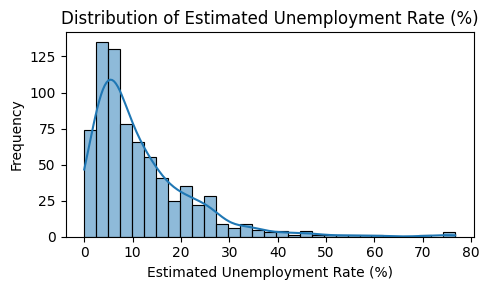

In [17]:
# Unemployment rate distribution
plt.figure(figsize=(5,3))
sns.histplot(
    data=df,
    x='Estimated Unemployment Rate (%)',
    kde=True
)
plt.title('Distribution of Estimated Unemployment Rate (%)')
plt.xlabel('Estimated Unemployment Rate (%)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

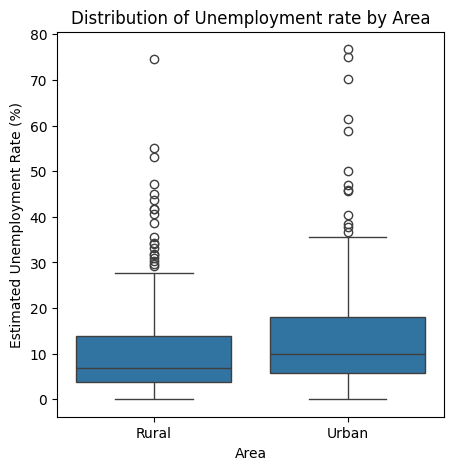

In [18]:
# Unemployment rate by Area
plt.figure(figsize=(5,5))
sns.boxplot(
    data=df,
    x='Area',
    y='Estimated Unemployment Rate (%)'
)
plt.title('Distribution of Unemployment rate by Area')
plt.xlabel('Area')
plt.ylabel('Estimated Unemployment Rate (%)')
plt.show()

In [19]:
area_unemployment=df.groupby('Area')['Estimated Unemployment Rate (%)'].mean()
display(area_unemployment)

,Estimated Unemployment Rate (%)
Area,
Rural,10.324791
Urban,13.166614


In [20]:
print('Average Unemployment rate by Area:')
display(area_unemployment)

Average Unemployment rate by Area:


,Estimated Unemployment Rate (%)
Area,
Rural,10.324791
Urban,13.166614


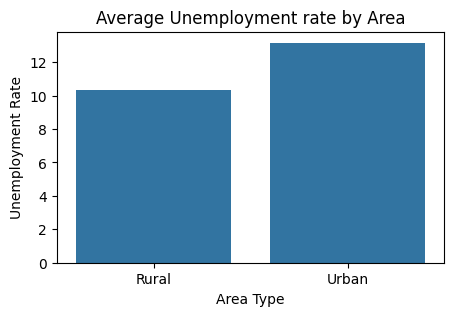

In [21]:
plt.figure(figsize=(5,3))
sns.barplot(
    x=area_unemployment.index,
    y=area_unemployment.values
)
plt.xlabel('Area Type')
plt.ylabel('Unemployment Rate')
plt.title('Average Unemployment rate by Area')
plt.show()

In [22]:
# Average unemployment rate by region
region_unemployment=(
    df.groupby('Region')['Estimated Unemployment Rate (%)'].mean().sort_values(ascending=False)
)

In [23]:
print('Average Unemployment Rate by Region:')
display(round(region_unemployment,2))

Average Unemployment Rate by Region:


,Estimated Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06


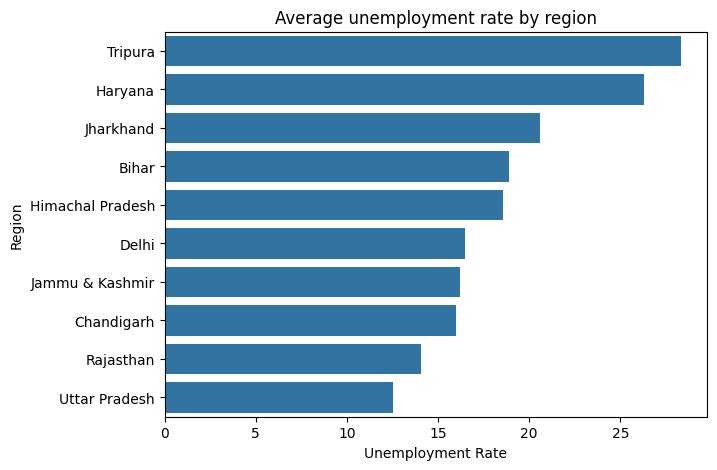

In [24]:
plt.figure(figsize=(7,5))
sns.barplot(
    x=region_unemployment.head(10).values,
    y=region_unemployment.head(10).index
)
plt.xlabel('Unemployment Rate')
plt.ylabel('Region')
plt.title('Average unemployment rate by region')
plt.show()

In [25]:
print('Top 10 Regions with lowest Unemployment Rate in India:')
display(region_unemployment.tail(10).sort_values())

Top 10 Regions with lowest Unemployment Rate in India:


,Estimated Unemployment Rate (%)
Region,
Meghalaya,4.798889
Odisha,5.657857
Assam,6.428077
Uttarakhand,6.582963
Gujarat,6.663929
Karnataka,6.676071
Sikkim,7.249412
Madhya Pradesh,7.406429
Andhra Pradesh,7.477143


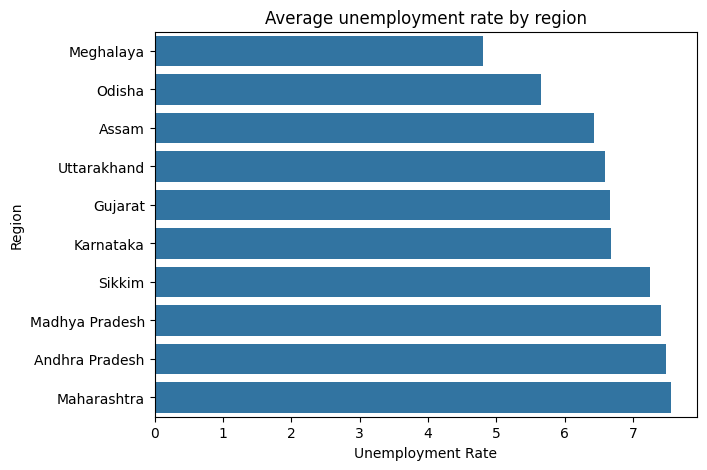

In [26]:
plt.figure(figsize=(7,5))
sns.barplot(
    x=region_unemployment.tail(10).sort_values().values,
    y=region_unemployment.tail(10).sort_values().index
)
plt.xlabel('Unemployment Rate')
plt.ylabel('Region')
plt.title('Average unemployment rate by region')
plt.show()

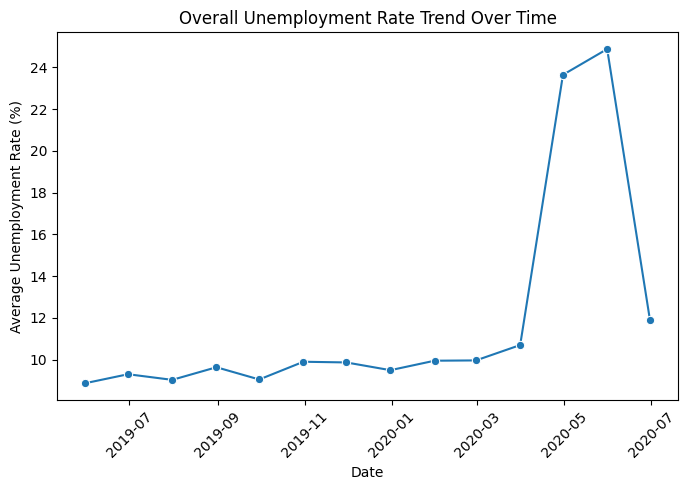

In [27]:
# Average Unemployment rate by Date
date_unemployment=(
    df.groupby('Date')['Estimated Unemployment Rate (%)'].mean().reset_index()
)
plt.figure(figsize=(7,5))
sns.lineplot(
    data=date_unemployment,
    x='Date',
    y='Estimated Unemployment Rate (%)',
    marker='o'
)
plt.title('Overall Unemployment Rate Trend Over Time')
plt.xlabel('Date')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
pre_covid=df[df['Date']<'2020-03-01']
covid_period=df[df['Date']>='2020-03-01']
avg_pre_covid=pre_covid['Estimated Unemployment Rate (%)'].mean()
avg_covid_period=covid_period['Estimated Unemployment Rate (%)'].mean()
print('Average Unemployment rate before covid:',round(avg_pre_covid,2))
print('Average Unemployment rate during covid:',round(avg_covid_period,2))
print("The difference in Unemployment rate before and during covid:",round((avg_covid_period-avg_pre_covid),2))

Average Unemployment rate before covid: 9.51
Average Unemployment rate during covid: 17.77
The difference in Unemployment rate before and during covid: 8.26


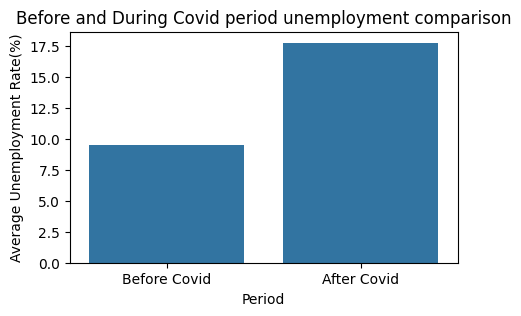

In [29]:
covid_comparison=pd.DataFrame({
    'Period':['Before Covid','After Covid'],
    'Average Unemployment Rate(%)':[avg_pre_covid,avg_covid_period]
})
plt.figure(figsize=(5,3))
sns.barplot(
    data=covid_comparison,
    x='Period',
    y='Average Unemployment Rate(%)'
)
plt.title('Before and During Covid period unemployment comparison')
plt.xlabel('Period')
plt.ylabel('Average Unemployment Rate(%)')
plt.show()

In [30]:
# Average Unemployment rate by Month
monthly_unemployment=(df.groupby('Month')['Estimated Unemployment Rate (%)'].mean())
print('Average Unemployment Rate by Month')
display(round(monthly_unemployment,2))

Average Unemployment Rate by Month


,Estimated Unemployment Rate (%)
Month,
1,9.95
2,9.96
3,10.70
4,23.64
5,16.65
6,10.55
7,9.03
8,9.64
9,9.05


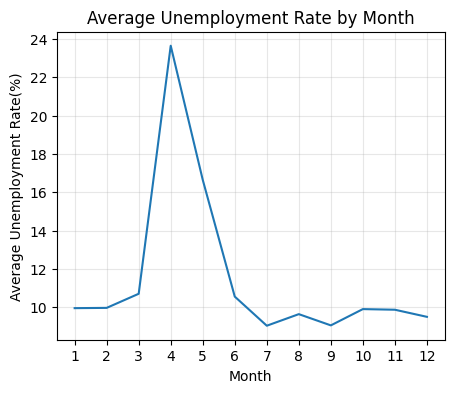

In [31]:
plt.figure(figsize=(5,4))
sns.lineplot(
    x=monthly_unemployment.index,
    y=monthly_unemployment.values
)
plt.title('Average Unemployment Rate by Month')
plt.xlabel('Month')
plt.ylabel('Average Unemployment Rate(%)')
plt.xticks(range(1,13))
plt.grid(True,alpha=0.3)
plt.show()

In [32]:
df.columns

Index(['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)',
       'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area',
       'Year', 'Month'],
      dtype='object')

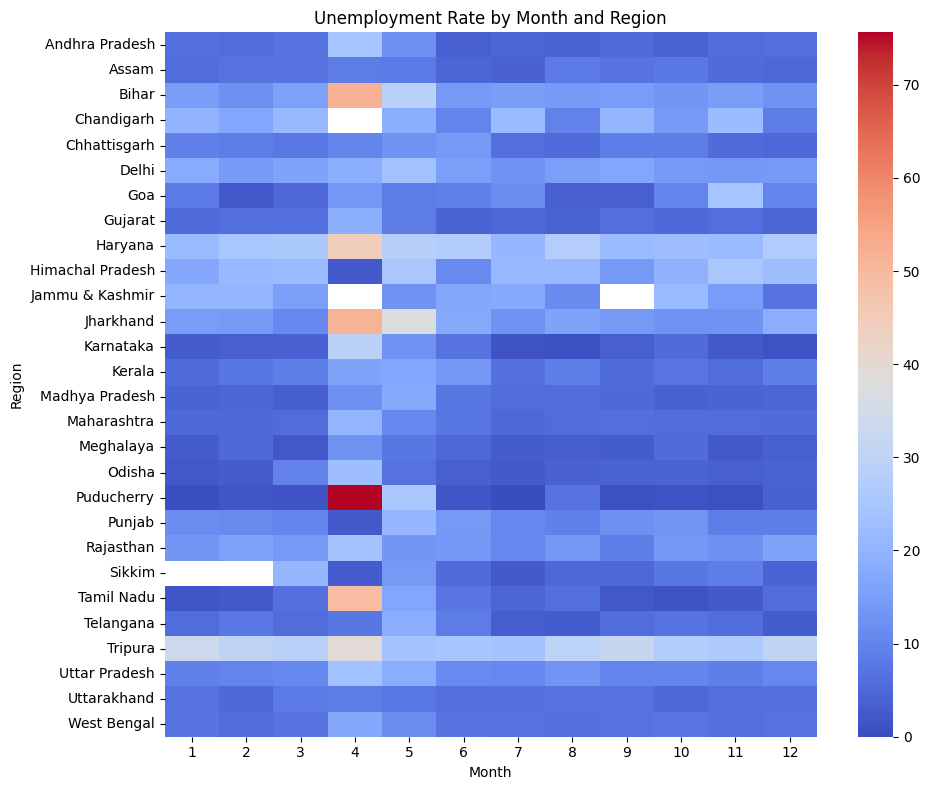

In [39]:
region_month=df.pivot_table(
    values='Estimated Unemployment Rate (%)',
    index='Region',
    columns='Month',
    aggfunc='mean'
)
plt.figure(figsize=(10,8))
sns.heatmap(
    region_month,
    cmap='coolwarm',
    annot=False
)
plt.title('Unemployment Rate by Month and Region')
plt.xlabel('Month')
plt.ylabel('Region')
plt.tight_layout()
plt.show()

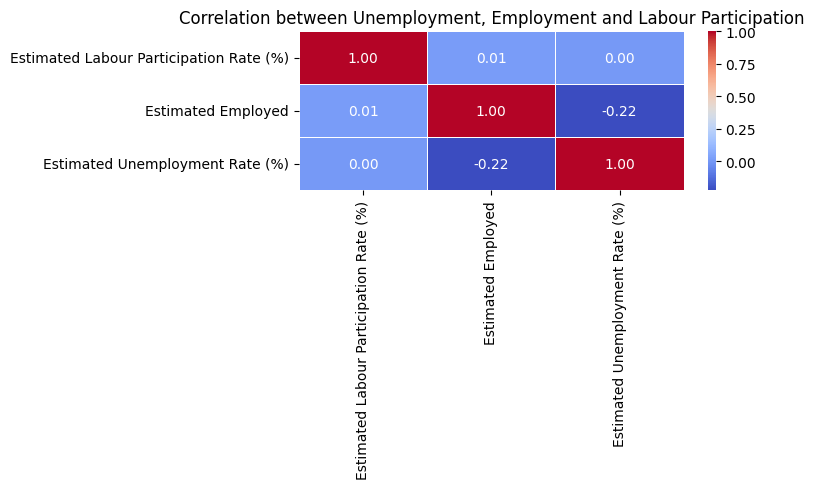

In [40]:
correlation_df=df[[
    'Estimated Labour Participation Rate (%)','Estimated Employed','Estimated Unemployment Rate (%)'
]]
correlation_matrix=correlation_df.corr()
plt.figure(figsize=(8,5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Correlation between Unemployment, Employment and Labour Participation')
plt.tight_layout()
plt.show()

In [41]:
# Unemployment rate summary
print('Unemplyment Rate Summary:')
display(df['Estimated Unemployment Rate (%)'].describe())

Unemplyment Rate Summary:


,Estimated Unemployment Rate (%)
count,740.000000
mean,11.787946
std,10.721298
min,0.000000
25%,4.657500
50%,8.350000
75%,15.887500
max,76.740000


In [44]:
# Average Unemployment rate by Area
print('Average Unemployment rate by Area:')
display(round(df.groupby('Area')['Estimated Unemployment Rate (%)'].mean(),2))

Average Unemployment rate by Area:


,Estimated Unemployment Rate (%)
Area,
Rural,10.32
Urban,13.17


In [49]:
# Highest Unemployment Rate by Regions
print('Top 5 Regions with highest unemploymnety Rate')
display(round(region_unemployment.head(),2))

Top 5 Regions with highest unemploymnety Rate


,Estimated Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54


In [50]:
# Lowes Unemployment Rate by Regions
print('Top 5 Regions with highest unemploymnety Rate')
display(round(region_unemployment.tail(),2).sort_values())

Top 5 Regions with highest unemploymnety Rate


,Estimated Unemployment Rate (%)
Region,
Meghalaya,4.80
Odisha,5.66
Assam,6.43
Uttarakhand,6.58
Gujarat,6.66


In [54]:
# Covid Period Feature
df['Covid_period']=np.where(
    df['Date']< '2020-03-01',
    'Pre-Covid',
    'Covid-Period')

display(df[['Date','Year','Month','Covid_period']])
display(df['Covid_period'].value_counts())

,Date,Year,Month,Covid_period
0,2019-05-31,2019,5,Pre-Covid
1,2019-06-30,2019,6,Pre-Covid
2,2019-07-31,2019,7,Pre-Covid
3,2019-08-31,2019,8,Pre-Covid
4,2019-09-30,2019,9,Pre-Covid
...,...,...,...,...
735,2020-02-29,2020,2,Pre-Covid
736,2020-03-31,2020,3,Covid-Period
737,2020-04-30,2020,4,Covid-Period
738,2020-05-31,2020,5,Covid-Period


,count
Covid_period,
Pre-Covid,536
Covid-Period,204


In [55]:
# Compare Unemployment Rate by Covid-Period
covid_period_unemployment=(
    df.groupby('Covid_period')['Estimated Unemployment Rate (%)'].mean().reset_index()
)
print('Unemployment Rate by Covid-Period')
display(round(covid_period_unemployment,2))

Unemployment Rate by Covid-Period


,Covid_period,Estimated Unemployment Rate (%)
0,Covid-Period,17.77
1,Pre-Covid,9.51


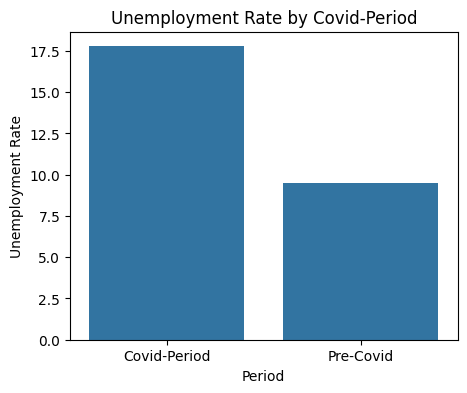

In [56]:
plt.figure(figsize=(5,4))
sns.barplot(
    data=covid_period_unemployment,
    x='Covid_period',
    y='Estimated Unemployment Rate (%)'
)
plt.xlabel('Period')
plt.ylabel('Unemployment Rate')
plt.title('Unemployment Rate by Covid-Period')
plt.show()

In [64]:
pre_covid_avg=round(df[df['Covid_period']=='Pre-Covid']['Estimated Unemployment Rate (%)'].mean(),2)
covid_avg=round(df[df['Covid_period']=='Covid-Period']['Estimated Unemployment Rate (%)'].mean(),2)

In [66]:
#percentage increase
percentage_increase=(
    ((covid_avg-pre_covid_avg)/pre_covid_avg)*100
)
print('Differnce Between Pre and During Covid:',covid_avg-pre_covid_avg)
print('Percentage Increase:',round(percentage_increase,2))

Differnce Between Pre and During Covid: 8.26
Percentage Increase: 86.86


In [69]:
# Unemployment rate by Month,Year and Covid-Period
monthly_unemployment_analysis=(
    df.groupby(['Date','Covid_period'])['Estimated Unemployment Rate (%)'].mean().reset_index()
)

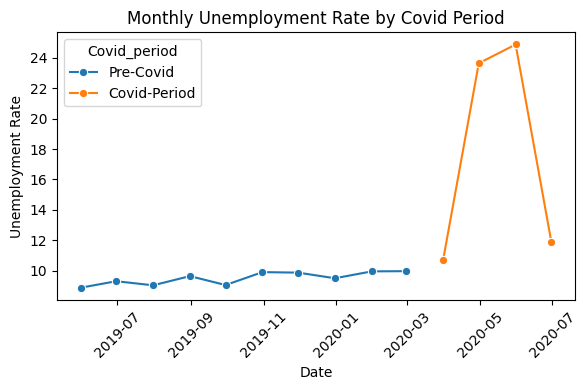

In [70]:
plt.figure(figsize=(6,4))
sns.lineplot(
    data=monthly_unemployment_analysis,
    x='Date',
    y='Estimated Unemployment Rate (%)',
    hue='Covid_period',
    marker='o'
)
plt.title('Monthly Unemployment Rate by Covid Period')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [71]:
df.to_csv('Unemployment_in_India(Covid)_cleaned.csv')

# Unemployment Analysis with Python

## Key Findings

1. **Unemployment Distribution:** The unemployment rate distribution is right-skewed, with most observations concentrated at lower rates and a few very high values.

2. **Rural vs Urban:** The average unemployment rate is approximately 10.4% in Rural areas and 13.2% in Urban areas in this dataset.

3. **Regional Analysis:** Average unemployment rates vary across regions. Tripura and Haryana appear among the regions with the highest averages in the analyzed data, while Meghalaya has the lowest.

4. **COVID-19 Impact:** The average unemployment rate increased from 9.51% before COVID-19 to 17.77% during the defined COVID period, a difference of 8.26 percentage points, or approximately 86.86% relative to the pre-COVID average.

5. **Monthly Trends:** The unemployment rate increased sharply in April and May 2020, then declined in June and July 2020.

6. **Regional Patterns:** The regional heatmap shows that unemployment rates varied across regions and months, with a noticeable increase in several regions during April 2020.

7. **Correlation Analysis:** Estimated unemployment rate and estimated employed have a weak negative correlation (-0.22), while the other examined pairs have correlations close to zero.

## Conclusion

The analysis shows variations in unemployment rates across regions and areas, along with a substantial increase during the COVID period in the dataset. Visualizations and summary statistics helped identify trends, regional differences and changes over time. These results describe the available data and do not independently establish the causes of unemployment changes.